In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
data = {
    'Practice_Tests_Completed': [0, 1, 2, 3, 4, 5, 1, 2, 3, 4],
    'Placement_Eligible': [0, 0, 0, 1, 1, 1, 0, 0, 1, 1]
}

df = pd.DataFrame(data)

print(df)

   Practice_Tests_Completed  Placement_Eligible
0                         0                   0
1                         1                   0
2                         2                   0
3                         3                   1
4                         4                   1
5                         5                   1
6                         1                   0
7                         2                   0
8                         3                   1
9                         4                   1


In [3]:
X = df[['Practice_Tests_Completed']]

y = df['Placement_Eligible']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:")
print(X_train)

print("Testing data:")
print(X_test)

Training data:
   Practice_Tests_Completed
8                         3
7                         2
1                         1
0                         0
4                         4
3                         3
5                         5
2                         2
Testing data:
   Practice_Tests_Completed
6                         1
9                         4


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [6]:
model = LogisticRegression()

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully")

Logistic Regression Model Trained Successfully


In [7]:
y_pred = model.predict(X_test_scaled)

print("Actual Values:", y_test.values)

print("Predicted Values:", y_pred)

Actual Values: [0 1]
Predicted Values: [0 1]


In [8]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 100.0 %


Confusion Matrix:
[[1 0]
 [0 1]]


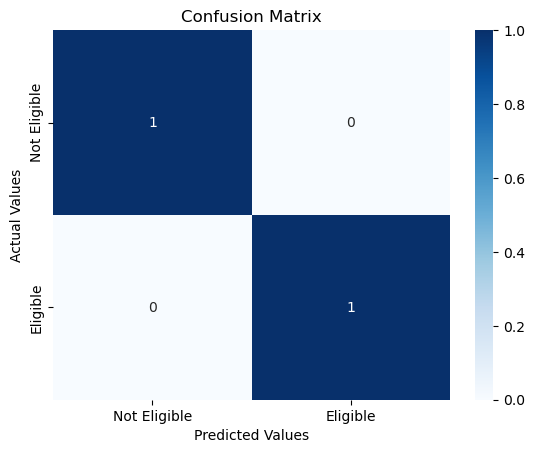

In [9]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Eligible', 'Eligible'],
    yticklabels=['Not Eligible', 'Eligible']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Confusion Matrix")
plt.show()

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Eligible', 'Eligible'],
    zero_division=0
))

              precision    recall  f1-score   support

Not Eligible       1.00      1.00      1.00         1
    Eligible       1.00      1.00      1.00         1

    accuracy                           1.00         2
   macro avg       1.00      1.00      1.00         2
weighted avg       1.00      1.00      1.00         2

